# Comparing root height estimates between skyline / constant coalescent prior

In [1]:
from Bio import Nexus, Phylo, SeqIO
from collections import defaultdict
from io import StringIO

import matplotlib.pyplot as plt
from matplotlib import gridspec

import seaborn as sns

import pandas as pd
import numpy as np

import re
from pathlib import Path

from itertools import combinations

from evaluation_helpers import *

In [ ]:
# filter to only look at roots
tree_metrics_combined = load_node_errors("../results/run1/evaluation")
root_height_df_wide = tree_metrics_combined[tree_metrics_combined['node_id'] == "internal_0"]
root_height_df_wide.to_csv("../results/run1/evaluation/root_height_info.csv", sep= "\t", index = False)

/Users/mariebecker/Documents/Uni/ETH/RotationStadler/BESP_paper-analyses/workflows/evaluation_helpers.py:3810: DtypeWarning: Columns (50,94) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs.append(pd.read_csv(tsv, sep="\t"))
/Users/mariebecker/Documents/Uni/ETH/RotationStadler/BESP_paper-analyses/workflows/evaluation_helpers.py:3810: DtypeWarning: Columns (50,94) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs.append(pd.read_csv(tsv, sep="\t"))
/Users/mariebecker/Documents/Uni/ETH/RotationStadler/BESP_paper-analyses/workflows/evaluation_helpers.py:3810: DtypeWarning: Columns (50,94) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs.append(pd.read_csv(tsv, sep="\t"))
/Users/mariebecker/Documents/Uni/ETH/RotationStadler/BESP_paper-analyses/workflows/evaluation_helpers.py:3810: DtypeWarning: Columns (50,94) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs.append(pd.r

In [3]:
root_height_df_wide = pd.read_csv("../results/run1/evaluation/root_height_info.csv", sep= "\t")
root_height_df_wide.head()

,tree_index,node_idx,node_id,internal,height_sim,bl_sim,constcoal_pop_diff_median,constcoal_pop_diff_hpd_lower,constcoal_pop_diff_hpd_upper,constcoal_pop_rel_error_median,...,skyline_height_est_hpd_lower,skyline_height_est_hpd_upper,skyline_bl_est_median,skyline_bl_est_hpd_lower,skyline_bl_est_hpd_upper,skyline_height_inside_ci,skyline_bl_inside_ci,sampling,population_model,mutation_signal
0,0,0,internal_0,True,2995.021345,0.0,-127.088000,-236.003536,-6.320547,-0.127088,...,4080.487948,4440.618703,NaN,NaN,NaN,False,NaN,independenthomochronous,bottleneck,high
1,1,0,internal_0,True,1797.360469,0.0,-154.919397,-258.509556,-44.732510,-0.154919,...,1922.481100,2087.252494,NaN,NaN,NaN,False,NaN,independenthomochronous,bottleneck,high
2,2,0,internal_0,True,3492.044982,0.0,-222.825124,-322.426036,-109.869521,-0.222825,...,5142.319345,5588.547079,NaN,NaN,NaN,False,NaN,independenthomochronous,bottleneck,high
3,3,0,internal_0,True,1312.193877,0.0,-36.616512,-148.634362,103.990956,-0.036617,...,1375.176615,1538.215136,NaN,NaN,NaN,False,NaN,independenthomochronous,bottleneck,high
4,4,0,internal_0,True,1743.065750,0.0,-189.882196,-281.729422,-63.797783,-0.189882,...,2030.322342,2236.236307,NaN,NaN,NaN,False,NaN,independenthomochronous,bottleneck,high


## Summary root height errors 

The root height summarizes how far back in time the inferred tree reaches. We take the root node (`internal_0`) from the per-node error table (`root_height_df_wide`), so there is one row per replicate. In all plots, each grey dot is one replicate, the coloured dot is the median across replicates, and the vertical bar is the 95 % HPD interval across replicates. The constant-size coalescent (blue) and Bayesian skyline (purple) are shown side by side for each mutation signal (low, medium, high).

### 1. Root age error                                                                                                                                                                                     
For each replicate, we compare the root height of every posterior tree sample with the true root height of the simulated tree:

- **Relative error** (`height_rel_error_median`): $(h_\text{post} - h_\text{true}) / h_\text{true}$. This shows systematic bias. Positive values mean the root is placed too far in the past (the tree is too old), negative
values mean it is too recent.
- **Absolute relative error** (`height_abs_rel_error_median`): $|h_\text{post} - h_\text{true}| / h_\text{true}$. This shows typical accuracy regardless of direction.

The value plotted per replicate is the median of the error over the posterior samples. Overview figures show all population models under heterochronous sampling (relative and absolute relative error) and under homochronous sampling (relative error). The table below shows the median values and 95% HPDs across replicates. 

### 2. Detailed view and difference between priors
For each population model under heterochronous sampling, a separate figure shows the absolute relative error. Next to it, a green column on a second y-axis shows the per-replicate relative difference between the two
priors' errors, $(\text{err}_\text{const} - \text{err}_\text{sky}) / \text{err}_\text{sky}$. Values above 0 mean the constant-size coalescent prior gives a larger root age error than the skyline prior. With `print_results=True`, the medians and HPD intervals of each group are printed.

### 3. HPD coverage of the root age
For each replicate and prior, we compute the 95 % HPD interval of the posterior root height and record whether the true root height lies inside it (`constcoal_height_inside_ci`, `skyline_height_inside_ci`). The coverage
heatmaps (one per sampling scheme) show one 2×2 contingency table per scenario (population model × mutation signal). The table gives the percentage of replicates in which the true root age is inside the HPD under both
priors, under only one of them, or under neither. For a well-calibrated posterior, about 95 % of replicates should contain the true value.

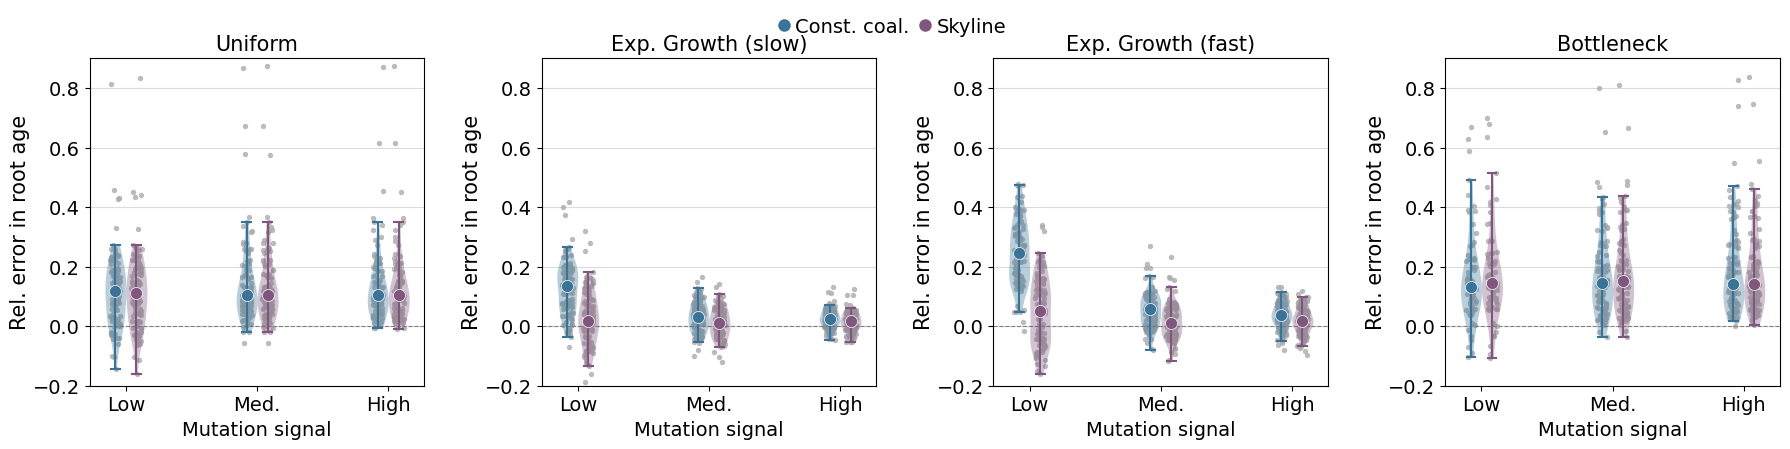

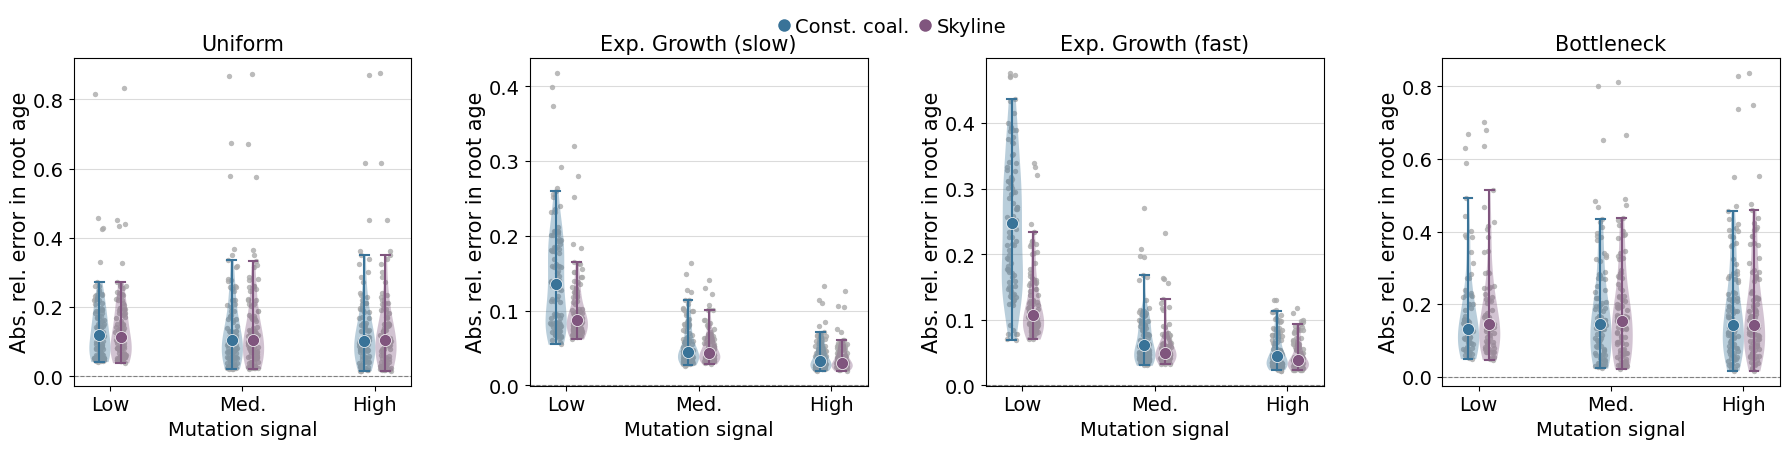

In [7]:
# rel. root age error
plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant',
                        y_col="height_rel_error_median", y_label="Rel. error in root age", y_range=(-0.2, 0.9),
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/root_height/summary_root_error_scatter_linearconstant_violin.pdf", violin = True)

# abs. rel. root age error
plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant',
                        y_col="height_abs_rel_error_median", y_label="Abs. rel. error in root age", y_range=None,
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/root_height/summary_abs_root_error_scatter_linearconstant_violin.pdf", violin = True)

uniform         Const. coal. low  mutsig  n=100  median=0.1183  95% HPD=(0.04291, 0.2712)
uniform         Const. coal. med  mutsig  n=100  median=0.1051  95% HPD=(0.02174, 0.3355)
uniform         Const. coal. high mutsig  n= 98  median=0.1038  95% HPD=(0.01662, 0.3502)
uniform         Skyline      low  mutsig  n=100  median=0.1143  95% HPD=(0.03947, 0.2722)
uniform         Skyline      med  mutsig  n=100  median=0.1043  95% HPD=(0.02286, 0.3345)
uniform         Skyline      high mutsig  n= 98  median=0.1041  95% HPD=(0.01625, 0.3503)
uniform         Const-Sky rel. diff.   low  mutsig  n=100  median=-0.004981  95% HPD=(-0.1058, 0.132)
uniform         Const-Sky rel. diff.   med  mutsig  n=100  median=-0.004644  95% HPD=(-0.06772, 0.06572)
uniform         Const-Sky rel. diff.   high mutsig  n= 98  median=-0.0007793  95% HPD=(-0.07448, 0.06624)


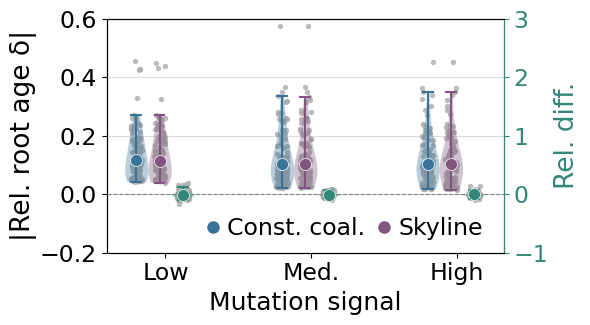

expgrowthfast   Const. coal. low  mutsig  n= 98  median=0.2474  95% HPD=(0.0698, 0.4367)
expgrowthfast   Const. coal. med  mutsig  n= 99  median=0.06175  95% HPD=(0.03058, 0.1681)
expgrowthfast   Const. coal. high mutsig  n=100  median=0.04483  95% HPD=(0.02369, 0.1127)
expgrowthfast   Skyline      low  mutsig  n= 98  median=0.107  95% HPD=(0.0706, 0.2346)
expgrowthfast   Skyline      med  mutsig  n= 99  median=0.0496  95% HPD=(0.03222, 0.1324)
expgrowthfast   Skyline      high mutsig  n=100  median=0.03805  95% HPD=(0.02291, 0.09347)
expgrowthfast   Const-Sky rel. diff.   low  mutsig  n= 98  median=1.074  95% HPD=(-0.363, 2.312)
expgrowthfast   Const-Sky rel. diff.   med  mutsig  n= 99  median=0.3206  95% HPD=(-0.4138, 0.8294)
expgrowthfast   Const-Sky rel. diff.   high mutsig  n=100  median=0.1982  95% HPD=(-0.3847, 0.5006)


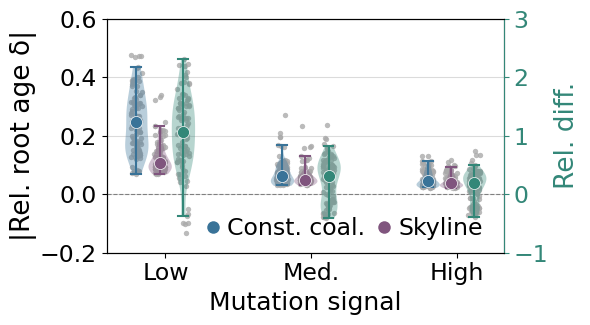

expgrowthslow   Const. coal. low  mutsig  n=100  median=0.1353  95% HPD=(0.0549, 0.2596)
expgrowthslow   Const. coal. med  mutsig  n=100  median=0.04468  95% HPD=(0.02737, 0.1146)
expgrowthslow   Const. coal. high mutsig  n=100  median=0.03196  95% HPD=(0.01968, 0.07139)
expgrowthslow   Skyline      low  mutsig  n=100  median=0.08723  95% HPD=(0.06186, 0.1648)
expgrowthslow   Skyline      med  mutsig  n=100  median=0.04344  95% HPD=(0.02855, 0.1006)
expgrowthslow   Skyline      high mutsig  n=100  median=0.02976  95% HPD=(0.01935, 0.06092)
expgrowthslow   Const-Sky rel. diff.   low  mutsig  n=100  median=0.5486  95% HPD=(-0.4825, 1.147)
expgrowthslow   Const-Sky rel. diff.   med  mutsig  n=100  median=0.11  95% HPD=(-0.328, 0.411)
expgrowthslow   Const-Sky rel. diff.   high mutsig  n=100  median=0.1085  95% HPD=(-0.2437, 0.2629)


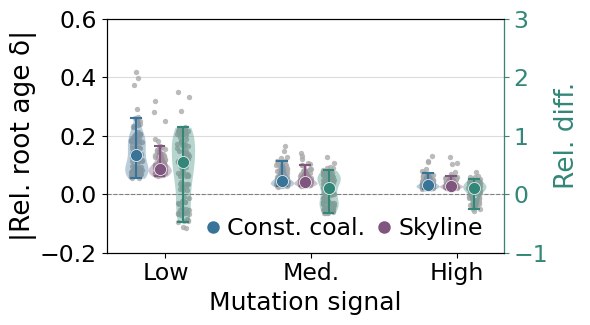

bottleneck      Const. coal. low  mutsig  n= 71  median=0.131  95% HPD=(0.04973, 0.4924)
bottleneck      Const. coal. med  mutsig  n= 94  median=0.146  95% HPD=(0.02351, 0.434)
bottleneck      Const. coal. high mutsig  n= 97  median=0.1413  95% HPD=(0.01703, 0.4575)
bottleneck      Skyline      low  mutsig  n= 71  median=0.1441  95% HPD=(0.04691, 0.5149)
bottleneck      Skyline      med  mutsig  n= 94  median=0.153  95% HPD=(0.02175, 0.437)
bottleneck      Skyline      high mutsig  n= 97  median=0.1415  95% HPD=(0.01616, 0.4605)
bottleneck      Const-Sky rel. diff.   low  mutsig  n= 71  median=-0.05502  95% HPD=(-0.2073, 0.05662)
bottleneck      Const-Sky rel. diff.   med  mutsig  n= 94  median=-0.01978  95% HPD=(-0.1418, 0.02264)
bottleneck      Const-Sky rel. diff.   high mutsig  n= 97  median=-0.01608  95% HPD=(-0.1015, 0.009357)


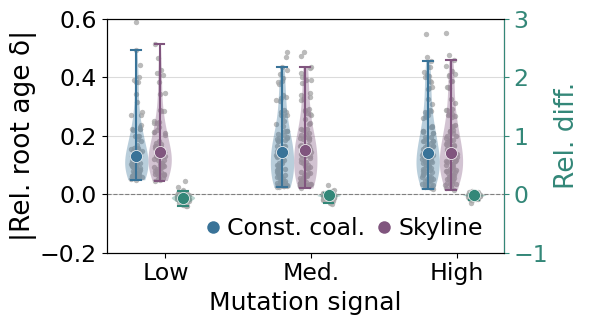

In [ ]:
# detailed plots for each population model
plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant', print_results=True,
                        y_col="height_abs_rel_error_median", y_label="|Rel. root age δ|", y_range = (-0.2, 0.6),
                        pop_models=['uniform'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range = (-1,3),
                        show_pop_model_labels = False, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/root_height/summary_abs_root_error_scatter_linearconstant_violin_uniform.pdf", violin = True)

plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant', print_results=True,
                        y_col="height_abs_rel_error_median", y_label="|Rel. root age δ|", y_range = (-0.2, 0.6),
                        pop_models=['expgrowthfast'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range = (-1, 3),
                        show_pop_model_labels = False, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/root_height/summary_abs_root_error_scatter_linearconstant_violin_expgrowthfast.pdf", violin = True)

plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant', print_results=True,
                        y_col="height_abs_rel_error_median", y_label="|Rel. root age δ|", y_range = (-0.2, 0.6),
                        pop_models=['expgrowthslow'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range = (-1, 3),
                        show_pop_model_labels = False, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/root_height/summary_abs_root_error_scatter_linearconstant_violin_expgrowthslow.pdf", violin = True)

plot_error_by_mutsig(root_height_df_wide, sampling = 'linearconstant', print_results=True,
                        y_col="height_abs_rel_error_median", y_label="|Rel. root age δ|", y_range = (-0.2, 0.6),
                        pop_models=['bottleneck'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range = (-1, 3),
                        show_pop_model_labels = False, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/root_height/summary_abs_root_error_scatter_linearconstant_violin_bottleneck.pdf", violin = True)

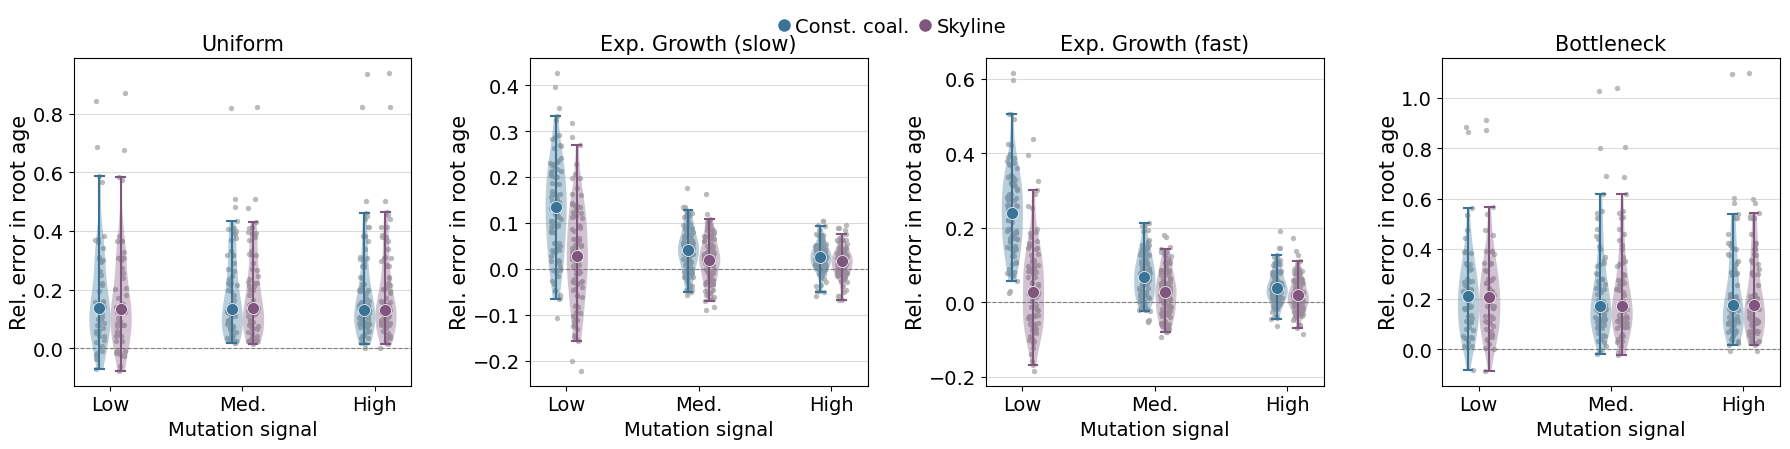

In [9]:
# homochronous sampling
plot_error_by_mutsig(root_height_df_wide, sampling = 'independenthomochronous',
                        y_col="height_rel_error_median", y_label="Rel. error in root age", y_range=None,
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/root_height/summary_root_error_scatter_independenthomochronous_violin.pdf", violin = True)

In [10]:
def hpd_lo(x): return hpd(x.dropna().values)[0]
def hpd_hi(x): return hpd(x.dropna().values)[1]

display(root_height_df_wide.groupby(['sampling', 'population_model', 'mutation_signal'])[['height_sim', 'constcoal_height_est_median', 'skyline_height_est_median']].agg(['median', hpd_lo, hpd_hi]))
display(root_height_df_wide.groupby(['sampling', 'population_model', 'mutation_signal'])[['height_sim', 'constcoal_height_abs_rel_error_median', 'skyline_height_abs_rel_error_median']].agg(['median', hpd_lo, hpd_hi]))

height_sim  \
                                                               median   
sampling                population_model mutation_signal                
independenthomochronous bottleneck       high             1766.056741   
                                         low              1885.920215   
                                         med              1837.239798   
                        expgrowthfast    high              215.185967   
                                         low               217.297147   
                                         med               214.044725   
                        expgrowthslow    high              360.924991   
                                         low               361.453048   
                                         med               360.327201   
                        uniform          high             1782.627191   
                                         low              1770.065750   
                                         med              1785.911950   
linearconstant          bottleneck       high             1780.455987   
                                         low              1735.694600   
                                         med              1756.552333   
                        expgrowthfast    high              216.177595   
                                         low               217.326795   
                                         med               215.143494   
                        expgrowthslow    high              357.756145   
                                         low               357.756145   
                                         med               357.756145   
                        uniform          high             1754.833042   
                                         low              1735.348804   
                                         med              1735.348804   

                                                                      \
                                                              hpd_lo   
sampling                population_model mutation_signal               
independenthomochronous bottleneck       high             498.834779   
                                         low              548.250333   
                                         med              596.282705   
                        expgrowthfast    high             175.104162   
                                         low              162.772552   
                                         med              154.627954   
                        expgrowthslow    high             260.014230   
                                         low              283.862548   
                                         med              260.014230   
                        uniform          high             575.250333   
                                         low              525.834779   
                                         med              804.612783   
linearconstant          bottleneck       high             761.489202   
                                         low              762.710391   
                                         med              761.489202   
                        expgrowthfast    high             185.578576   
                                         low              176.845957   
                                         med              176.845957   
                        expgrowthslow    high             258.454873   
                                         low              258.454873   
                                         med              258.454873   
                        uniform          high             574.043440   
                                         low              574.043440   
                                         med              574.043440   

                                                                       \
                                                               hpd_hi

height_sim  \
                                                               median   
sampling                population_model mutation_signal                
independenthomochronous bottleneck       high             1766.056741   
                                         low              1885.920215   
                                         med              1837.239798   
                        expgrowthfast    high              215.185967   
                                         low               217.297147   
                                         med               214.044725   
                        expgrowthslow    high              360.924991   
                                         low               361.453048   
                                         med               360.327201   
                        uniform          high             1782.627191   
                                         low              1770.065750   
                                         med              1785.911950   
linearconstant          bottleneck       high             1780.455987   
                                         low              1735.694600   
                                         med              1756.552333   
                        expgrowthfast    high              216.177595   
                                         low               217.326795   
                                         med               215.143494   
                        expgrowthslow    high              357.756145   
                                         low               357.756145   
                                         med               357.756145   
                        uniform          high             1754.833042   
                                         low              1735.348804   
                                         med              1735.348804   

                                                                      \
                                                              hpd_lo   
sampling                population_model mutation_signal               
independenthomochronous bottleneck       high             498.834779   
                                         low              548.250333   
                                         med              596.282705   
                        expgrowthfast    high             175.104162   
                                         low              162.772552   
                                         med              154.627954   
                        expgrowthslow    high             260.014230   
                                         low              283.862548   
                                         med              260.014230   
                        uniform          high             575.250333   
                                         low              525.834779   
                                         med              804.612783   
linearconstant          bottleneck       high             761.489202   
                                         low              762.710391   
                                         med              761.489202   
                        expgrowthfast    high             185.578576   
                                         low              176.845957   
                                         med              176.845957   
                        expgrowthslow    high             258.454873   
                                         low              258.454873   
                                         med              258.454873   
                        uniform          high             574.043440   
                                         low              574.043440   
                                         med              574.043440   

                                                                       \
                                                               hpd_hi

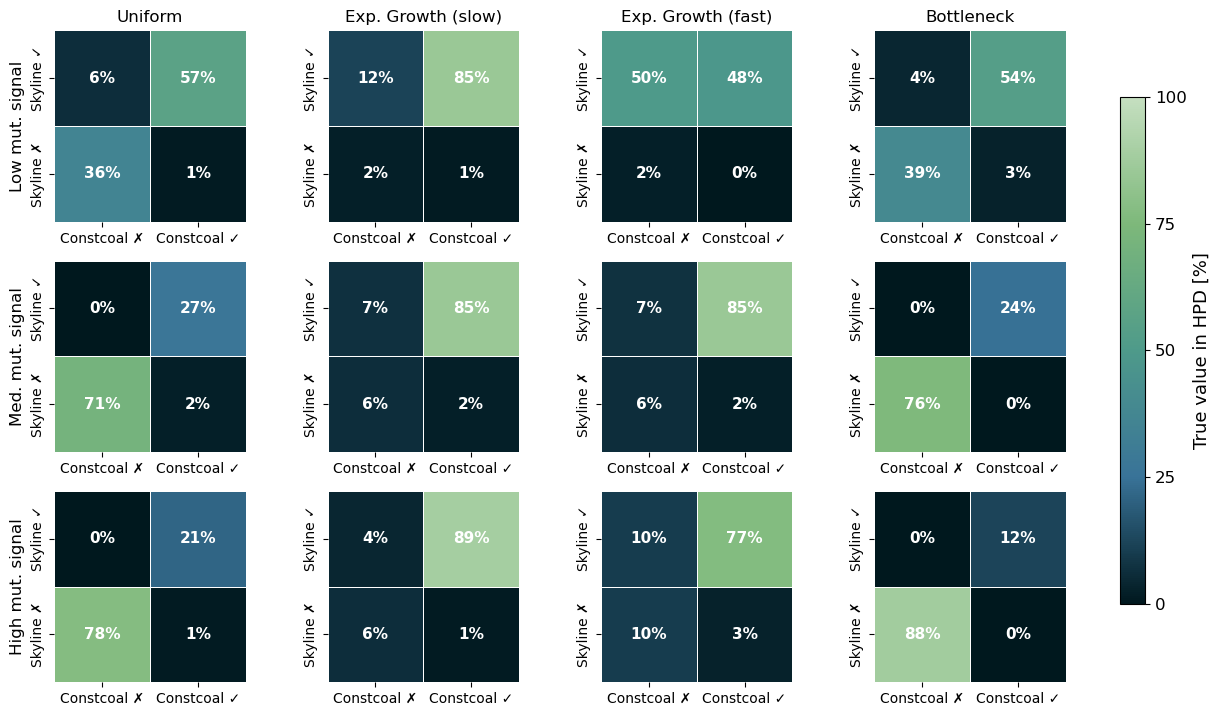

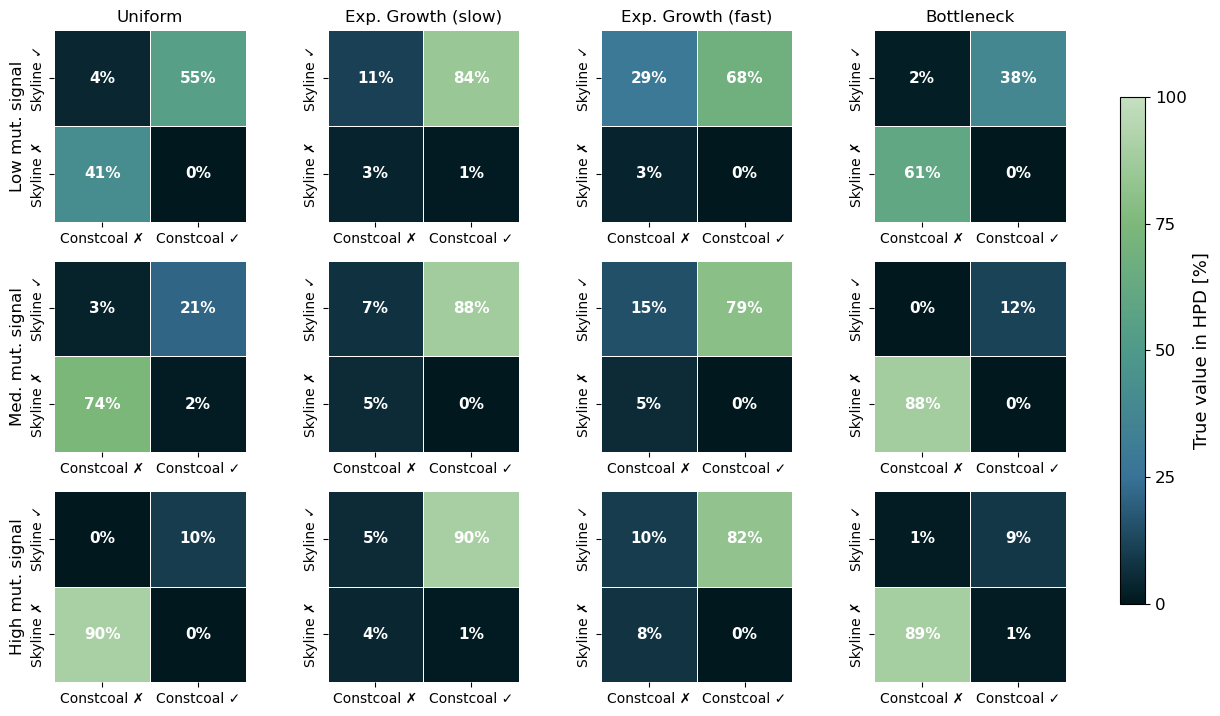

In [ ]:
# heterochronous sampling
plot_ci_coverage_heatmap(root_height_df_wide, sampling = 'linearconstant', title = "", save_path= "../figures/root_height/hpd_coverage_heatmap_linearconstant.pdf", cbar_label = "True value in HPD [%]")

# homochronous sampling
plot_ci_coverage_heatmap(root_height_df_wide, sampling = 'independenthomochronous', title = "", save_path= "../figures/root_height/hpd_coverage_heatmap_independenthomochronous.pdf", cbar_label = "True value in HPD [%]")

## Per root plots
### 4.  Root age error vs. population size error at the root
For each replicate, the relative root age error is plotted against the relative error in the coalescent rate $1/N_e$. The rate error is evaluated at the true root height and is the median over posterior samples. One point 
is one replicate, and each prior has its own colour. A second version colours points by the true root height (log-scaled colour bar), and a third plots the absolute root age error instead. These are shown for 
heterochronous sampling, and the relative error is also shown for homochronous sampling.

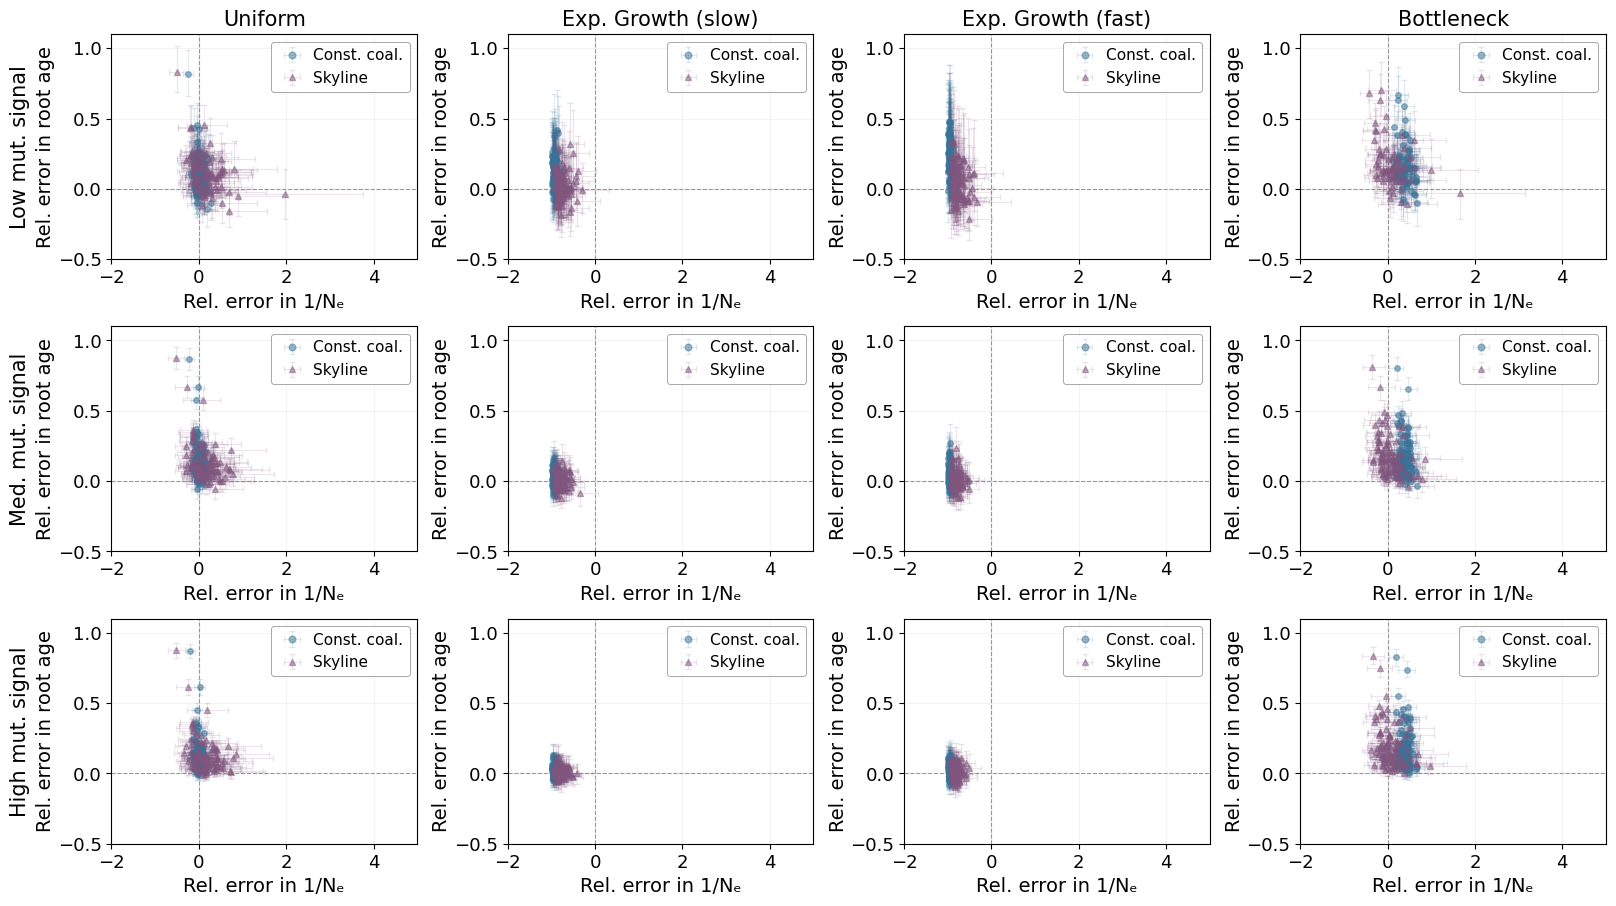

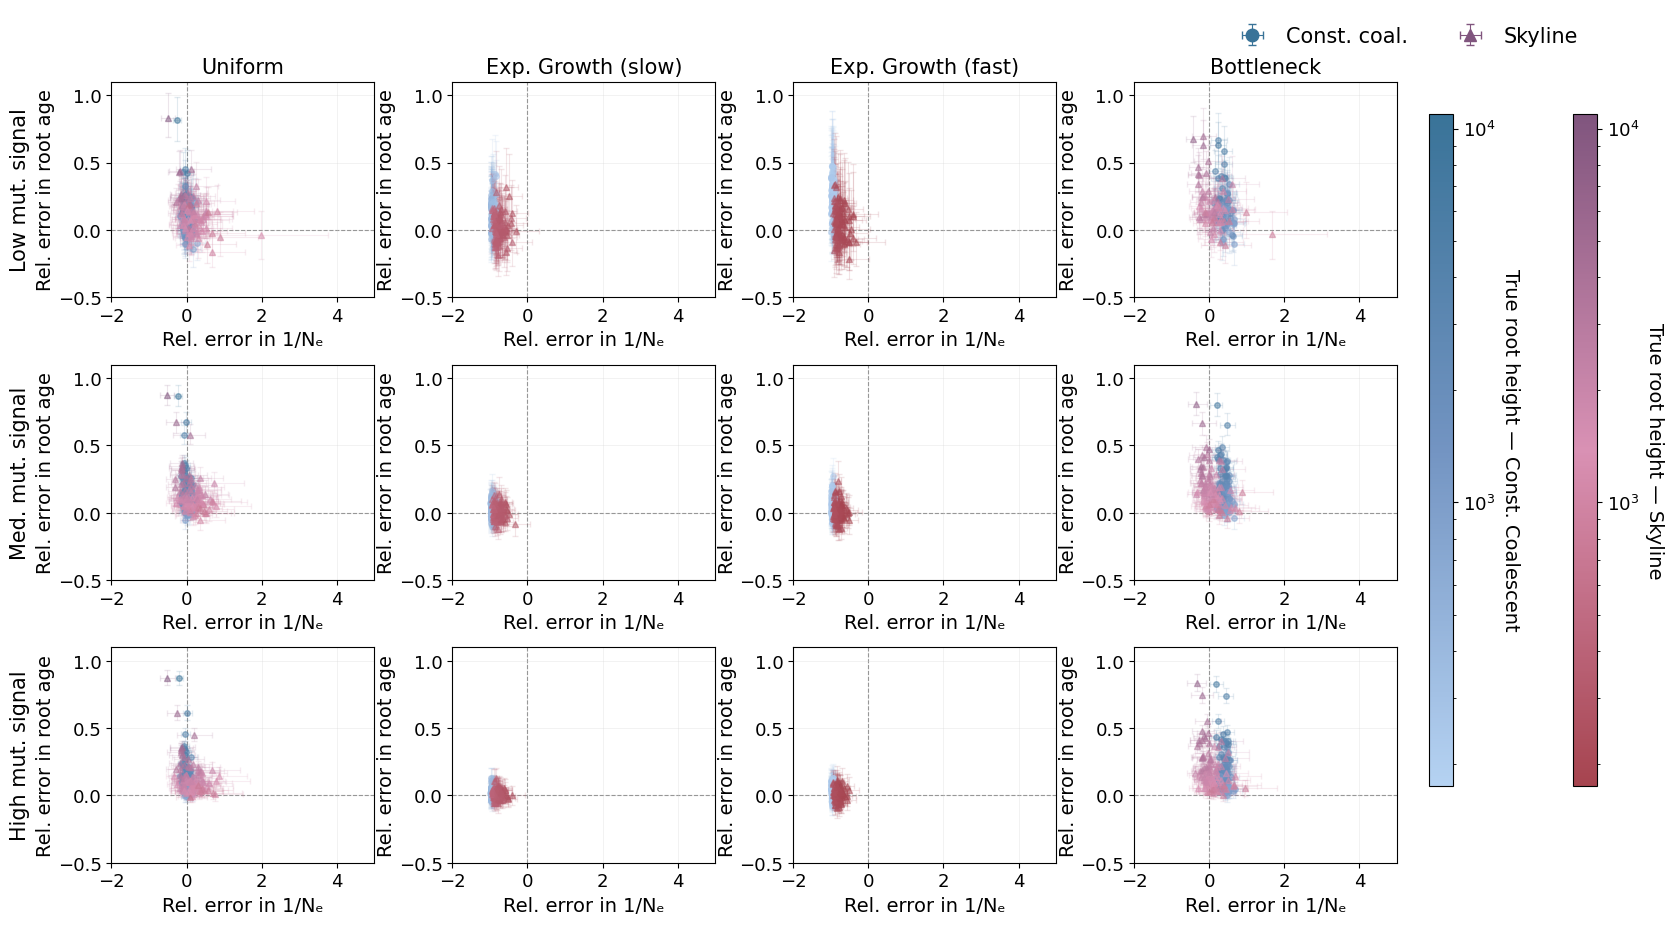

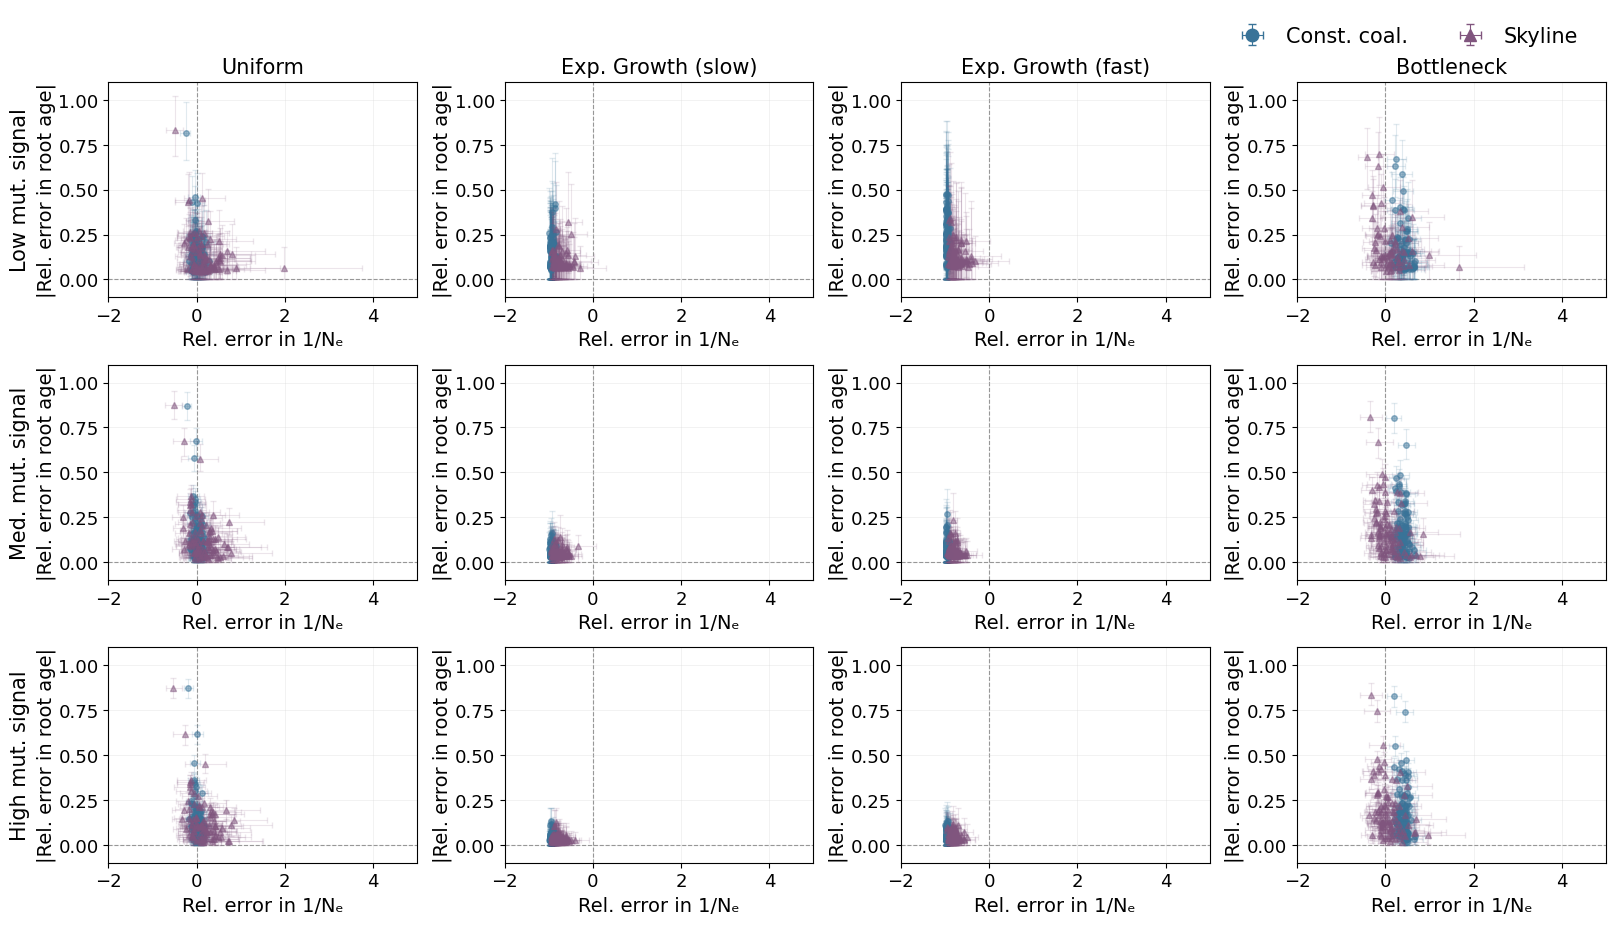

In [ ]:
# heterochronous sampling

# rel. error in root age vs rel. error in 1/Ne
plot_height_vs_popsize_error(root_height_df_wide, sampling="linearconstant", x_col="rate_rel_error_median", y_col="height_rel_error_median", alpha = 0.5, s = 20, y_range = (-0.5,1.1), x_range = (-2,5), pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'], x_label = "Rel. error in 1/Nₑ", y_label = "Rel. error in root age", title = "", save_path="../figures/root_height/rootheight_rate_error_linearconstant_all_legendin.pdf", legend_inside = True)
# colored by time
plot_height_vs_popsize_error(root_height_df_wide, sampling="linearconstant", x_col="rate_rel_error_median", y_col="height_rel_error_median", alpha = 0.5, s = 20, y_range = (-0.5, 1.1), x_range = (-2,5), pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'], x_label = "Rel. error in 1/Nₑ", y_label = "Rel. error in root age", title = "", save_path="../figures/root_height/rootheight_rate_error_linearconstant_all_legendout_timecoloring.pdf", legend_inside = False,
                                color_by_time=True, time_col = "height_sim", log_colorbar=True)
# absolute rel. error in root age
plot_height_vs_popsize_error(root_height_df_wide, sampling="linearconstant", x_col="rate_rel_error_median", y_col="height_abs_rel_error_median", alpha = 0.5, s = 20, y_range = (-0.1, 1.1), x_range = (-2,5), pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'], x_label = "Rel. error in 1/Nₑ", y_label = "|Rel. error in root age|", title = "", save_path="../figures/root_height/abs_rootheight_rate_error_linearconstant_all_legendout.pdf", legend_inside = False)

# homochronous sampling
plot_height_vs_popsize_error(root_height_df_wide, sampling="independenthomochronous", x_col="rate_rel_error_median", y_col="height_rel_error_median", alpha = 0.5, s = 20, x_range = (-3,12), y_range = (-0.3,1.3), pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'], x_label = "Rel. error in 1/Nₑ", y_label = "Rel. error in root age", title = "", save_path="../figures/root_height/rootheight_rate_error_independenthomochronous_all_legendin.pdf", legend_inside = True)

### 5. Root age error: constant coalescent vs. skyline
Each replicate is plotted as one point. The x-axis is the relative root age error under the skyline prior, the y-axis is the same error under the constant-coalescent prior, and both are medians over posterior samples.
Error bars show the 95 % HPD intervals of the error under each prior. Points are coloured by the true root height (log-scaled colour bar). The dashed diagonal marks equal errors under both priors: points above it have a
larger root age error under the constant-coalescent prior. Detailed plots show low mutation signal under heterochronous sampling for the uniform, fast exponential growth and bottleneck scenarios. Overview figures show all
population models and mutation signals for both sampling schemes.

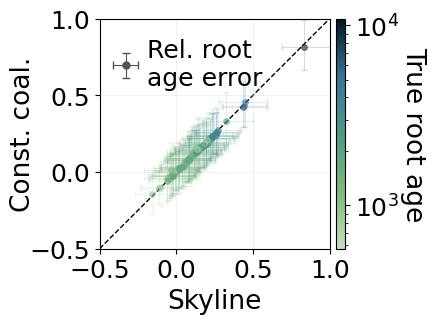

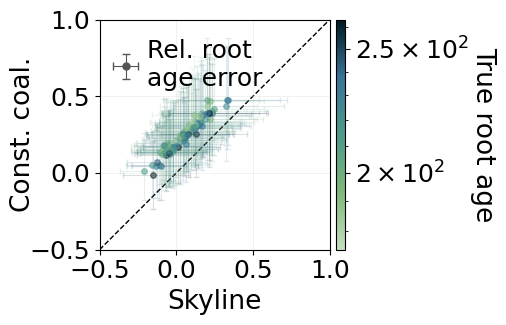

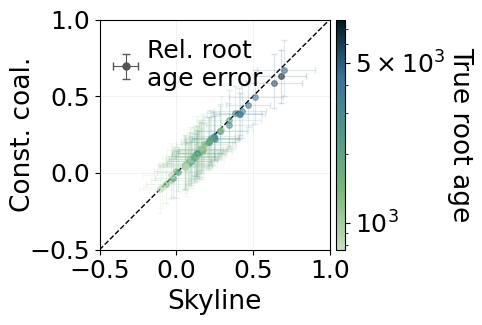

In [12]:
plot_constcoal_vs_skyline_error(root_height_df_wide, sampling="linearconstant",
                                   error_col="height_rel_error_median", error_label = 'Rel. root \n' \
                                   'age error',
                                   x_label="Skyline", y_label="Const. coal.",
                                   x_range = (-0.5, 1), y_range = (-0.5,1), figsize = (6, 3.5),
                                   title = "", label_fontsize=19, tick_fontsize=18, legend_fontsize=18, cbar_tick_fontsize=18,
                                   pop_models = ['uniform'], mutsigs = ['low'], show_pop_model_labels = False, show_mutsig_labels = False,
                                   color_by_time = True, time_col = 'height_sim', log_colorbar = True,
                                   save_path="../figures/root_height/skyline_constcoal_comparison_relrootheighterror_colored_uniform.pdf")

plot_constcoal_vs_skyline_error(root_height_df_wide, sampling="linearconstant",
                                   error_col="height_rel_error_median", error_label = 'Rel. root \n' \
                                   'age error',
                                   x_label="Skyline", y_label="Const. coal.",
                                   x_range = (-0.5, 1), y_range = (-0.5,1), figsize = (6, 3.5),
                                   title = "", label_fontsize=19, tick_fontsize=18, legend_fontsize=18, cbar_tick_fontsize=18,
                                   pop_models = ['expgrowthfast'], mutsigs = ['low'], show_pop_model_labels = False, show_mutsig_labels = False,
                                   color_by_time = True, time_col = 'height_sim', log_colorbar = True,
                                   save_path="../figures/root_height/skyline_constcoal_comparison_relrootheighterror_colored_expgrowthfast.pdf")

plot_constcoal_vs_skyline_error(root_height_df_wide, sampling="linearconstant",
                                   error_col="height_rel_error_median", error_label = 'Rel. root \n' \
                                   'age error',
                                   x_label="Skyline", y_label="Const. coal.",
                                   x_range = (-0.5, 1), y_range = (-0.5,1), figsize = (6, 3.5),
                                   title = "", label_fontsize=19, tick_fontsize=18, legend_fontsize=18, cbar_tick_fontsize=18,
                                   pop_models = ['bottleneck'], mutsigs = ['low'], show_pop_model_labels = False, show_mutsig_labels = False,
                                   color_by_time = True, time_col = 'height_sim', log_colorbar = True,
                                   save_path="../figures/root_height/skyline_constcoal_comparison_relrootheighterror_colored_bottleneck.pdf")

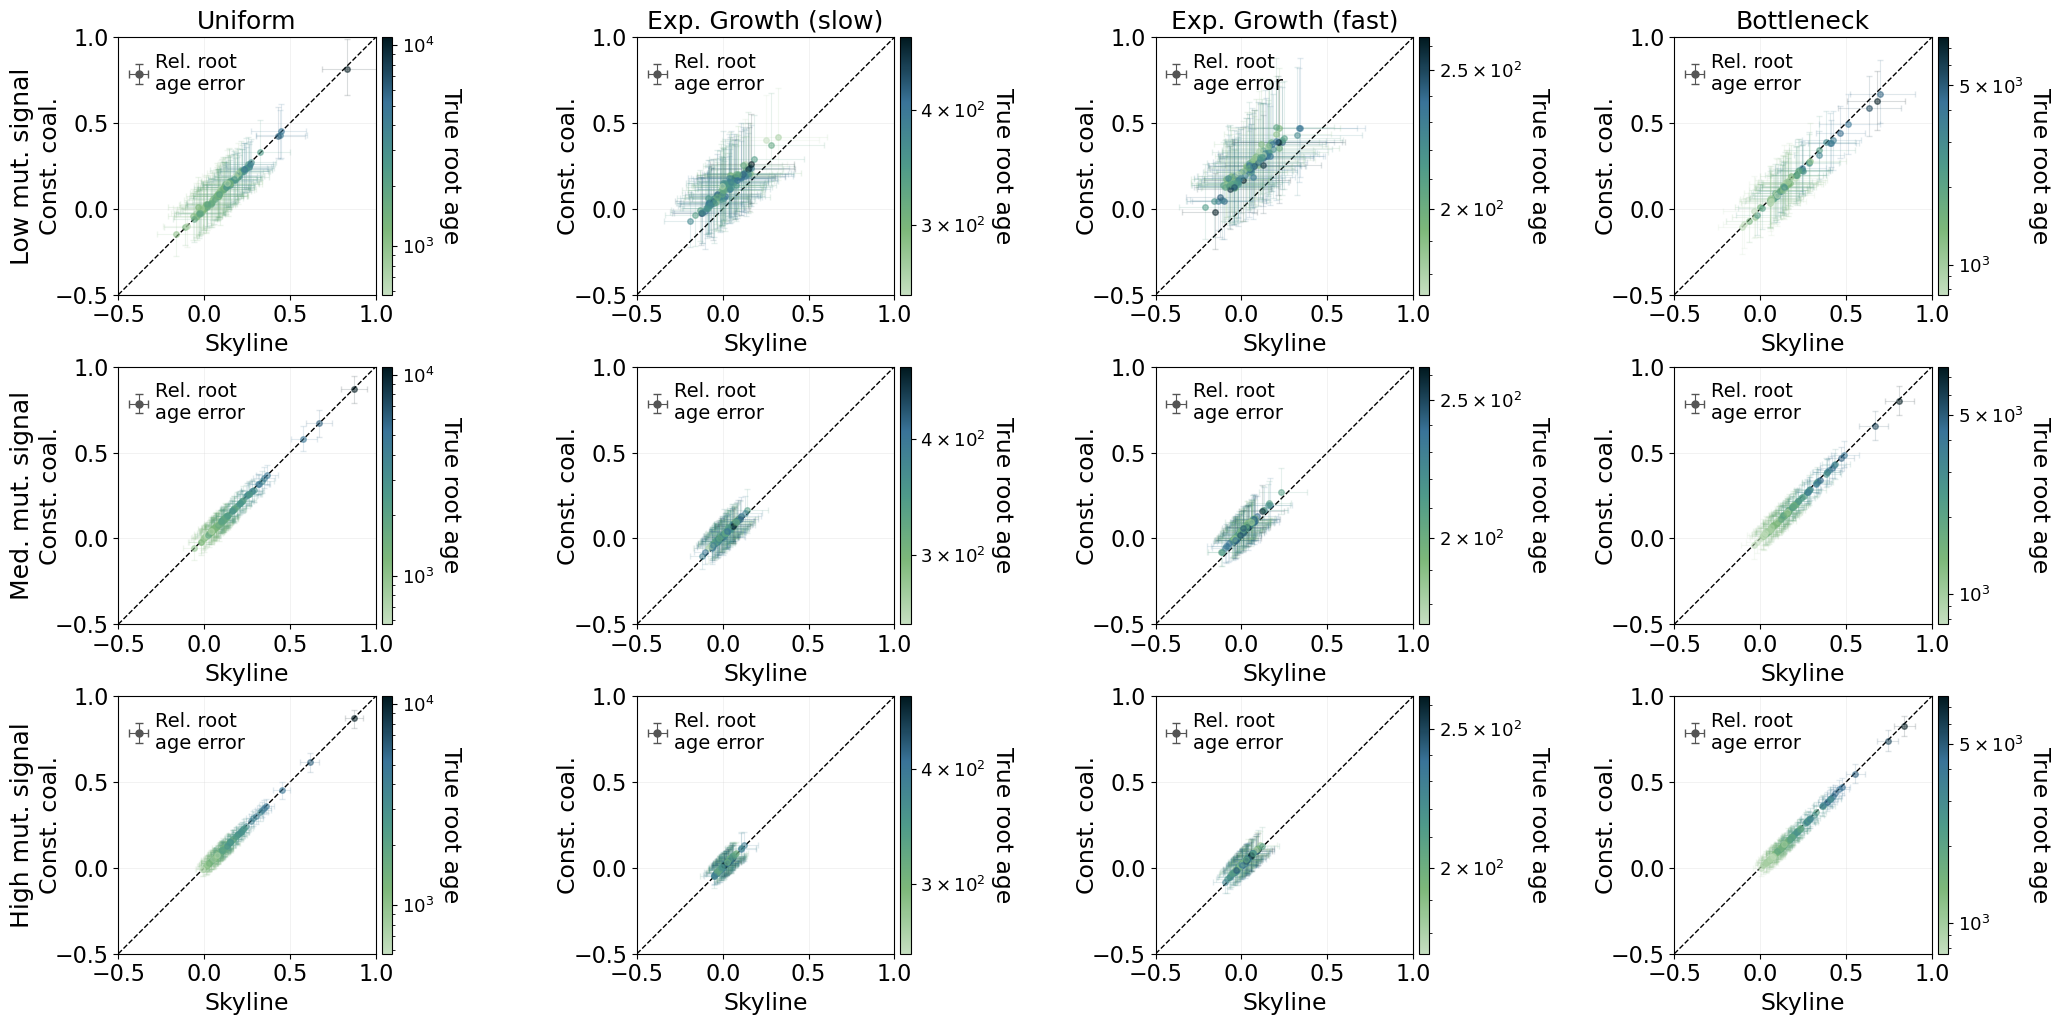

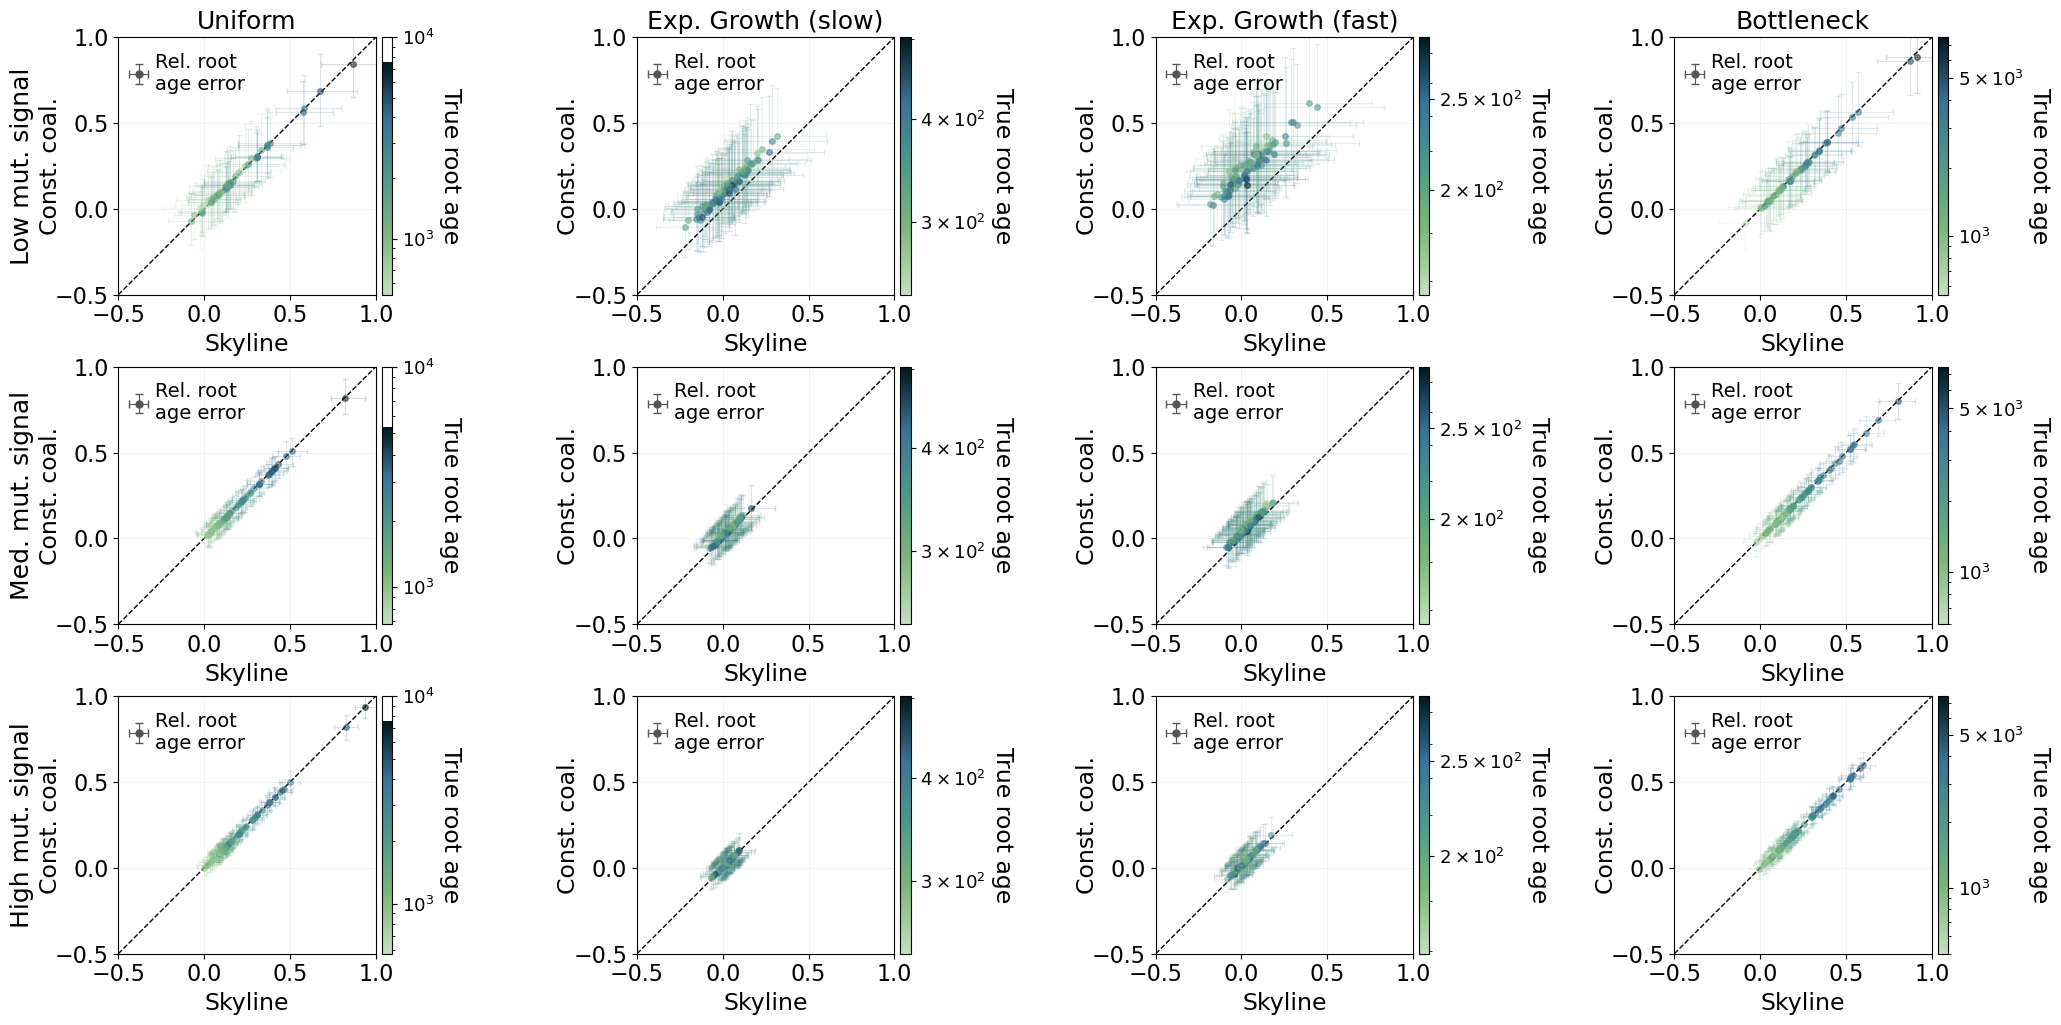

In [14]:
# heterochronous sampling
plot_constcoal_vs_skyline_error(root_height_df_wide, sampling="linearconstant",
                                   error_col="height_rel_error_median", error_label = 'Rel. root \n' \
                                   'age error',
                                   x_label="Skyline", y_label="Const. coal.",
                                   x_range = (-0.5, 1), y_range = (-0.5,1),
                                   title = "",
                                   color_by_time = True, time_col = 'height_sim', log_colorbar = True,
                                   save_path="../figures/root_height/skyline_constcoal_comparison_relrootheighterror_colored.pdf")

# homochronous sampling
plot_constcoal_vs_skyline_error(root_height_df_wide, sampling="independenthomochronous",
                                   error_col="height_rel_error_median", error_label = 'Rel. root \n' \
                                   'age error',
                                   x_label="Skyline", y_label="Const. coal.",
                                   x_range = (-0.5, 1), y_range = (-0.5,1),
                                   title = "",
                                   color_by_time = True, time_col = 'height_sim', log_colorbar = True,
                                   save_path="../figures/root_height/skyline_constcoal_comparison_relrootheighterror_colored_independenthomochronous.pdf")